# Assign and Add · как трансформер учится складывать значения переменных

### Исследовательский вопрос

Пусть в контексте записано `c = 54`. Чтобы ответить на запрос `c + 9`, модель должна найти значение `c`, сложить 54 и 9 и вернуть 4 по модулю 59. Если она верно решает `54 + 9`, решит ли она и вариант с `c`? В работе Exoo, Bietti и Sous эти две способности можно наблюдать по отдельности в ходе обучения.

[Статья Assign and Add](https://arxiv.org/html/2605.31497v1) · [Протокол опытов, данные и диагностика](../experiments/assign-add-implementation.md)

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
# Jupyter может начать работу в корне репозитория или в notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "icl_lab" / "runtime.py").is_file():
    ROOT = ROOT.parent
if not (ROOT / "src" / "icl_lab" / "runtime.py").is_file():
    raise RuntimeError("Откройте ноутбук из корня репозитория или каталога notebooks/.")
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
import assign_notebook as lab

series_dir = ROOT / "artifacts/runs/assign-add-jupyter-20261119"
seeds = (1, 2, 3)
%matplotlib inline

## Как устроен один эпизод

Эпизод — один пример задачи на сложение. В нём заданы $k$ разных переменных из 12 возможных имён $a,b,\ldots,l$, где $1\leq k\leq6$. У каждой своё значение из $\mathbb Z_{59}=\{0,1,\ldots,58\}$. Значения разных переменных могут совпадать. В новом эпизоде присваивания делаются заново.

**Как генератор составляет задачу**

1. Выбирает упорядоченную пару чисел $(u,v)$ и формат запроса. Каждый операнд можно записать числом или именем. Получаются четыре формата: число + число, имя + число, число + имя, имя + имя.
2. Для каждого имени в запросе добавляет присваивание нужного значения. Если в запросе два имени, они различны. Оставшимся переменным присваивает случайные числа. Эти присваивания тоже видны модели, хотя для ответа они не нужны.
3. Перемешивает присваивания и укладывает их в первые 12 токенов. Имя и значение стоят рядом, свободные позиции заполняются токеном `PAD`. Последние четыре токена — запрос `+ левый_операнд правый_операнд =`. Правильный ответ $(u+v)\bmod 59$ хранится отдельно.

**Один пример целиком.** В строке `test[8]` выбраны $k=2$ переменные, $f=31$ и $d=32$. Вот все 16 токенов, которые получает модель:

```text
PAD PAD PAD PAD f 31 PAD d 32 PAD PAD PAD + f d =
```

Метка этого примера — **4**, поскольку $(31+32)\bmod 59=4$. В следующей ячейке показаны один свежий обучающий эпизод и три строки тестового набора сида 1. Таблица опускает заполнители и показывает числа после подстановки в столбце «Операнды». Для просмотра других примеров поменяйте номера в `rows`. [Генератор эпизодов](../src/icl_lab/tasks/assign_add.py)

In [3]:
run = series_dir / 'seed-1'
rows = [4, 8, 18]
examples = lab.preview_data(run, rows)
display(pd.DataFrame(examples).set_index('Источник'))

,Присваивания,Запрос,Операнды,Ответ
Источник,,,,
новый train,"d=16, l=7, c=9, e=58",2 + 21,2 + 21,23
test[4],a=27,a + 17,27 + 17,44
test[8],"f=31, d=32",f + d,31 + 32,4
test[18],"b=47, g=40, h=7, d=39, a=10, c=37",29 + b,29 + 47,17


## Как модель получает ответ и чему мы её обучаем

Каждый из 16 токенов заменяется вектором размерности 128, к которому прибавляется обучаемый вектор его позиции. Последовательность проходит через два блока трансформера. В каждом работает одна голова **masked self-attention**: позиция видит себя и все предыдущие токены. Во втором блоке за вниманием следует MLP со скрытым слоем ширины 512 и ReLU. Вектор последнего токена `=` уже учитывает и присваивания, и запрос. Линейная проекция превращает этот вектор в 59 логитов — по одному на каждый возможный остаток. [Схема модели](../figures/assign-add/Assign%20and%20Add.excalidraw) · [Реализация](../src/icl_lab/tasks/assign_add.py)

На каждом шаге генератор выдаёт **512 новых эпизодов**. Для каждого модель предсказывает сумму, а cross-entropy сравнивает логиты с правильным остатком. По среднему loss батча AdamW обновляет веса модели (learning rate 0,001). Один запуск длится 30 000 шагов. Мы повторяем его с тремя сидами: меняются начальные веса и поток обучающих примеров. [Конфигурация](../configs/experiments/assign_add.yaml)

**Для работы с готовыми весами** оставьте `START_TRAINING = False` и переходите к загрузке модели ниже.

**Для нового обучения** выберите свободное имя `NEW_SERIES`, поставьте `START_TRAINING = True` и выполните следующую ячейку. Она поставит все три сида в очередь на MPS. В новом каталоге появятся `worker.log`, состояние очереди `series-state.json` и подкаталог каждого сида с конфигом, журналами и весами. Когда очередь получит статус `completed`, верните флаг в `False`, укажите новый каталог в `series_dir` в начале ноутбука и выполните **Run All**. [Скрипт запуска](../scripts/run-assign-series.py)

In [4]:
START_TRAINING = False
NEW_SERIES = 'assign-add-reader-01'

if START_TRAINING:
    import sys
    from icl_lab.runtime import ROOT
    sys.path.insert(0, str(ROOT / 'scripts'))
    from assign_notebook import launch_new_series
    print('Каталог новой серии:', launch_new_series(NEW_SERIES))
else:
    print('Просмотр готовых весов. Новое обучение выключено.')

Просмотр готовых весов. Новое обучение выключено.


### Что обученная модель ответит на наши три запроса?

Ячейка восстанавливает модель сида 1 из конфига и финальных весов `checkpoints/final.pt`. Для тех же строк `rows` она подаёт на вход последовательности токенов и на CPU выбирает ответ с наибольшим логитом. В таблице рядом стоят предсказание модели и правильная сумма из тестового набора. [Загрузка весов](../src/icl_lab/engine.py) · [Вызов из ноутбука](../scripts/assign_notebook.py)

In [5]:
predictions = lab.predict_examples(run, rows)
display(pd.DataFrame(predictions).set_index('Строка test'))

,Запрос,Правильный ответ,Предсказание
Строка test,,,
4,a + 17,44,44
8,f + d,4,4
18,29 + b,17,17


## Проверка на знакомых и новых сочетаниях

Как проверить, что модель умеет складывать в условиях, которых не было при обучении? Для этого при подготовке данных задаются два ограничения.

- **Какие числа можно складывать.** Из $59^2$ упорядоченных пар заранее выбираются 2436 для обучения (около 70%). Остальные 1045 откладываются. Ограничение действует на значения после подстановки переменных. Пары $(31,32)$ и $(32,31)$ учитываются отдельно.
- **Где может стоять имя.** В обучающих запросах `a` и `b` могут стоять только слева, `k` и `l` — только справа. Ограничение касается операндов запроса. Все эти имена могут появляться среди присваиваний в контексте.

При запуске генератор один раз сохраняет тестовые наборы в `banks/*.npz`. Все три модели оцениваются на одних и тех же эпизодах.

| Набор | Как составлен эпизод |
|---|---|
| **ID** | Новый контекст и запрос с разрешённой числовой парой и знакомыми позициями имён. |
| **OOD** | Меняется одно условие. Либо берётся отложенная пара чисел при знакомых позициях, как в `test[8]`, либо берётся знакомая пара, но одно или два имени стоят на новых сторонах запроса. |

Для каждого сида ячейка сверяет идентификаторы эпизодов, сопоставляет предсказания финальной модели с метками и считает долю верных ответов отдельно на 12 000 ID- и 12 000 OOD-эпизодов. [Подготовка наборов и оценка](../src/icl_lab/engine.py)

In [6]:
scores = lab.check_final_scores(series_dir, seeds)
final = scores.pivot(index=["seed", "step"], columns="split", values="accuracy")
final = final.rename(columns={"id_test": "ID", "test": "OOD"})
display(final.rename_axis(index=["Сид", "Шаг"], columns=None).style.format("{:.3%}"))

,,ID,OOD
Сид,Шаг,,
1,30000,99.975%,99.250%
2,30000,71.100%,47.300%
3,30000,99.933%,98.967%


В серии 19 ноября на новых сочетаниях модели с сидами 1 и 3 дали около 99% верных ответов. У сида 2 точность составила 47,30% на OOD и 71,10% на ID: он ошибается и при знакомых условиях. Чтобы выяснить, где возникает разрыв, посмотрим отдельно на запросы с числами и с переменными.

## Какие результаты статьи повторяются на наших моделях?

Авторы исследовали, когда в ходе обучения модель осваивает сложение и как она использует значения переменных. У нас есть два способа это проверить. По промежуточным весам проследим, когда растёт точность разных типов запросов. Затем по финальным весам проверим сложение отдельно от поиска значений в контексте.

### В каком порядке модель осваивает числа и переменные?

В основном запуске статьи точность сначала выросла на сложении двух чисел, позже — на запросах с переменными. Особенно долго модель училась находить значение, когда уже знакомое имя появлялось с новой стороны запроса. [Статья, рис. 2](https://arxiv.org/html/2605.31497v1#S4)

В **верхнем ряду** у всех запросов отложенная числовая пара. Слева направо меняется запись операндов: два числа, одна переменная, две переменные. В **нижнем ряду** пара чисел знакомая. Сначала одна переменная стоит на новой стороне. В двух следующих панелях запрос содержит две переменные, и на новой стороне находится одна из них или обе.

По горизонтали — тысячи шагов обучения, по вертикали — доля верных ответов. Одна линия соответствует одному сиду. Каждая точка рассчитана по 2000 эпизодов той же группы.

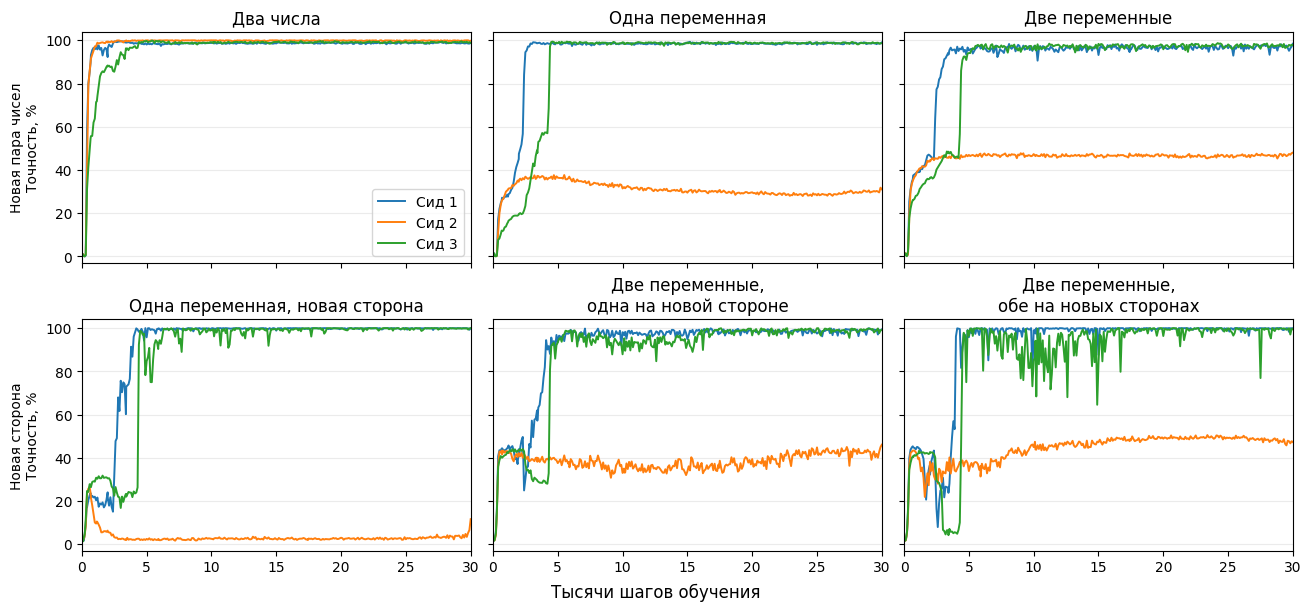

In [7]:
history = lab.evaluation_history(series_dir, seeds)
groups = {
    '0var_add_ood': 'Два числа',
    '1var_add_ood': 'Одна переменная',
    '2var_add_ood': 'Две переменные',
    '1var_position_ood': 'Одна переменная, новая сторона',
    '2var_position_ood_1': 'Две переменные,\nодна на новой стороне',
    '2var_position_ood_2': 'Две переменные,\nобе на новых сторонах',
}
ood = history.query("split == 'test' and group != 'all'")
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True, layout='constrained')
for ax, (group, title) in zip(axes.flat, groups.items()):
    panel = ood[ood['group'] == group]
    for seed, curve in panel.groupby('seed'):
        ax.plot(curve['step'] / 1000, 100 * curve['accuracy'], lw=1.4, label=f'Сид {seed}')
    ax.set(title=title, ylim=(-3, 104), xlim=(0, 30))
    ax.grid(axis='y', alpha=0.25)
axes[0, 0].set_ylabel('Новая пара чисел\nТочность, %')
axes[1, 0].set_ylabel('Новая сторона\nТочность, %')
axes[0, 0].legend(loc='lower right')
fig.supxlabel('Тысячи шагов обучения')
plt.show()

В серии 19 ноября посмотрим, на каком шаге точность **впервые достигла 95%**. Оба столбца относятся к отложенным числовым парам. Первый показывает запросы с двумя числами, второй — с двумя переменными.

| Сид | Два числа | Две переменные на знакомых сторонах |
|---:|---:|---:|
| 1 | 800 шагов | 3500 шагов |
| 2 | 900 шагов | Порог не достигнут за 30 000 шагов |
| 3 | 3400 шагов | 5200 шагов |

В двух из трёх наших запусков порог был пройден в том же порядке, что и в статье. У сида 2 сложение двух чисел тоже появилось рано, но до конца обучения ни одна OOD-группа с переменными не достигла 95%.

У двух правых панелей нижнего ряда есть важная особенность. В этих группах у авторов от двух до шести присваиваний встречаются одинаково часто, а наш генератор выбирает ровно два присваивания с вероятностью 1/3. Если при подсчёте дать каждой длине одинаковый вес, финальная точность сида 2 снизится с 46,05% и 47,25% до 35,35% в обеих группах. Графики показывают точность на исходном составе нашего теста. [Сопоставление тестовых наборов](../experiments/assign-add-implementation.md#сопоставимость-с-авторами-и-воспроизводимость)

### Что получится, если сразу дать модели правильные операнды?

Возьмём два числа $u,v\in\mathbb Z_{59}$ и их обученные эмбеддинги $e_u,e_v$. Чтобы проверить само сложение, исключим из вычисления выбор позиций по attention. Подадим оба эмбеддинга напрямую на проекции value и output головы второго слоя (вместе $OV_2$), сложим полученные векторы и применим MLP второго блока и выходную проекцию $W_U$. Для пары $(u,v)$ получатся логиты

$$
W_U\,\mathrm{MLP}_2\big(OV_2(e_u)+OV_2(e_v)\big).
$$

Ячейка загружает финальные веса каждого сида и на CPU проверяет, совпадает ли индекс максимального логита с $(u+v)\bmod 59$ на всех 3481 парах. У авторов эта проверка дала **99,94%** на всех парах. На графике эта точка относится к столбцу «Все пары»; рядом показаны наши результаты отдельно на знакомых и отложенных парах. [Статья, §5.1](https://arxiv.org/html/2605.31497v1#S5.SS1)

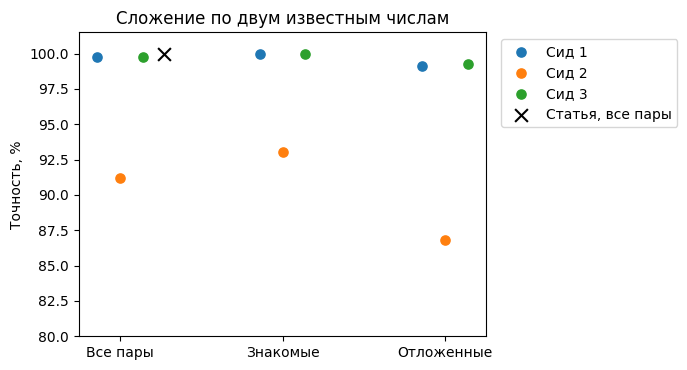

In [8]:
circuit = lab.final_circuit_data(series_dir, seeds)

columns = {'accuracy': 'Все пары', 'seen_accuracy': 'Знакомые', 'held_out_accuracy': 'Отложенные'}
scores = 100 * circuit.set_index('seed')[list(columns)].rename(columns=columns)
lower = min(80, 5 * np.floor(scores.min().min() / 5))
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(columns))
for offset, (seed, values) in zip(np.linspace(-0.14, 0.14, len(scores)), scores.iterrows()):
    ax.scatter(x + offset, values, s=44, label=f'Сид {seed}')
ax.set(xlabel='', ylabel='Точность, %', ylim=(lower, 101.5), title='Сложение по двум известным числам')
ax.set_xticks(range(len(columns)), list(columns.values()))
ax.scatter([0.27], [99.94], marker='x', s=85, color='black', label='Статья, все пары')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.figure.tight_layout()
plt.show()

В серии 19 ноября на всех парах точность изолированного сложения составила 99,74% у сида 1, 99,77% у сида 3 и 91,18% у сида 2. На отложенных парах сид 2 решил 86,79% примеров. Значит, часть ошибок возможна даже при подаче правильных чисел. Отдельно проверим, может ли ошибка возникнуть раньше, когда модель выбирает нужное значение среди токенов.

## Наш эксперимент · как имя переменной меняет ответ сида 2

Возьмём два эпизода с одной и той же знакомой арифметической парой $(4,3)$. Позиции присваивания и запроса в них одинаковы.

| Присваивание | Запрос | Что меняется для модели | Цель |
|---|---|---|---:|
| $c=3$ | $4+c$ | Имя $c$ встречалось справа при обучении | 7 |
| $a=3$ | $4+a$ | При обучении имя $a$ встречалось только слева в запросе | 7 |

Авторы наблюдали, что для отдельных имён передача значения осваивается позже. На финальных весах сида 2 проверим, можно ли исправить ответ для $a$, изменив только **то, откуда второй слой читает значения**. [Статья, §6](https://arxiv.org/html/2605.31497v1#S6)

В позиции `=` второй слой вычисляет по одному весу внимания для каждой позиции входа. Сохраняем эту строку весов из прогона с $c$ и подставляем её в парный прогон с $a$. Векторы значений и остаточная ветвь берутся из прогона с $a$. Дальше модель сама вычисляет выход MLP и ответ.

Повторяем вмешательство на всех **2397** знакомых парах $(u,v)$ с $u\ne v$. На них удвоение явного числа $2u$ всегда можно отличить от правильной суммы $u+v$ по модулю 59. Для контроля переносим внимание из эпизода с $c$, но с другой парой чисел. Затем проверяем обратное направление переноса — с $a$ на $c$. График построен по сохранённым измерениям сида 2 исходной серии. [Код опыта](../scripts/diagnose-assign-binding.py) · [Измерения](../artifacts/records/assign-add-binding-20261120.json)

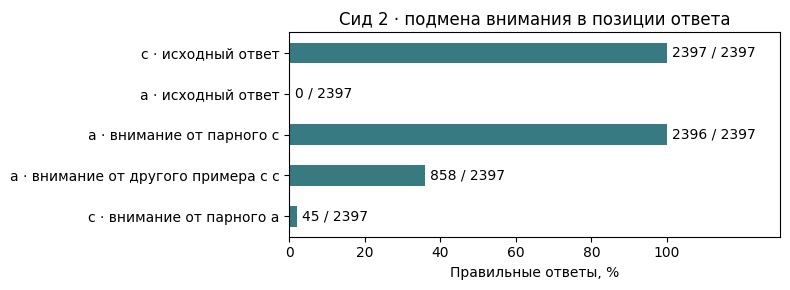

In [9]:
record = json.loads((ROOT / "artifacts/records/assign-add-binding-20261120.json").read_text())
if series_dir.resolve() != (ROOT / record["run"]).resolve() or 2 not in seeds:
    print("Для выбранной серии и сидов этот парный опыт не показан. Он проводился на сиде 2 исходной серии.")
else:
    patch = record["seeds"]["2"]["name_attention_patch"]
    conditions = {
        "native_c": "c · исходный ответ",
        "native_a": "a · исходный ответ",
        "a_with_c_attention": "a · внимание от парного c",
        "a_with_unpaired_c_attention": "a · внимание от другого примера с c",
        "c_with_a_attention": "c · внимание от парного a",
    }
    correct = pd.Series({label: patch["correct"][key] for key, label in conditions.items()})
    ax = (100 * correct / patch["n"]).plot.barh(figsize=(8, 3), color="#387a82")
    ax.invert_yaxis()
    ax.set(xlabel="Правильные ответы, %", xlim=(0, 130), xticks=range(0, 101, 20),
           title="Сид 2 · подмена внимания в позиции ответа")
    ax.bar_label(ax.containers[0], labels=[f"{n} / {patch['n']}" for n in correct], padding=4)
    plt.tight_layout()
    plt.show()

**Что изменил перенос внимания.** С именем $c$ справа сид 2 решил все 2397 примеров. С именем $a$ он во всех 2397 случаях вернул удвоенное явное число (для $4+a$ это 8). Когда модель получила строку внимания от парного примера с $c$, правильный ответ вернулся в **2396 из 2397** случаев. Внимание от другой пары чисел дало только 858 верных ответов. Обратная замена испортила ответы на запросах с $c$: правильными остались 45.

На этих коротких входах достаточно изменить выбор позиций во втором слое, чтобы исправить почти все ошибки. Строка внимания зависит и от представлений первого слоя, поэтому остаётся открытым вопрос, как именно при обучении возникло такое поведение и сохранится ли оно после 30 000 шагов. Для входов с несколькими присваиваниями есть отдельный опыт: там проверяли, меняется ли ответ вслед за значением посторонней переменной. [Опыт с посторонними присваиваниями](../experiments/assign-add-implementation.md#как-постороннее-присваивание-меняет-ответ)